In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os


In [4]:
# Load the File path from Dekstop to python to loan the file for analysis 

FOLDER = r"C:\Users\gagan\Downloads\Portfolios\credit risk Project\Python Actions for Raw data Modifications"
df = pd.read_parquet(FOLDER + r"\lc_clean_v1.parquet")
os.makedirs(FOLDER + r"\charts", exist_ok=True)
print(df.shape)

(546018, 36)


In [5]:
# SQL query 4 - Check the real rate of default by checking the Portfolio mix and its reason of change- KITAGAWA DECOMPOSITION
 # It teels that the Rising default rates across each grades(3.11) are the primary factor for increased default rates 
 # While Portfolio Mix change helps to Decrese a little bit of this(-0.55) due to which overall risk default rate remain high (2.56) 
rate = df.groupby(["grade", "issue_year"])["bad"].mean().unstack()
mix = pd.crosstab(df["grade"], df["issue_year"], normalize="columns")

total  = (mix[2015] * rate[2015]).sum() - (mix[2013] * rate[2013]).sum()
mix_ef = ((mix[2015] - mix[2013]) * rate[2013]).sum()
within = (mix[2015] * (rate[2015] - rate[2013])).sum()
print(round(100 * total, 2), round(100 * mix_ef, 2), round(100 * within, 2))

2.56 -0.55 3.11


In [6]:
# Percentage of row data missing in which columns of loan dataset
miss = df.isna().mean().sort_values(ascending = False)
print(miss[miss>0].round(4))

mths_since_last_delinq    0.4983
emp_length                0.0615
emp_length_yrs            0.0615
utilization               0.0005
obligation_ratio          0.0000
dtype: float64


In [7]:
# WE Now check is there is an link between a employment_ years(emp_length_yrs) of person missing and its impact on default rates
print(df.groupby(df["emp_length_yrs"].isna())["bad"].mean().round(3))

emp_length_yrs
False    0.136
True     0.206
Name: bad, dtype: float64


In [8]:
# HANDLE MISSING VALUES (IMPUTATION) TO PREPARE DATA FOR MODELING

df["emp_missing_flag"] = df["emp_length_yrs"].isna().astype(int)
df["emp_length_yrs"] = df["emp_length_yrs"].fillna(df["emp_length_yrs"].median())
df["mths_since_last_delinq"] = df["mths_since_last_delinq"].fillna(999)
for c in ["utilization","obligation_ratio"]:
    df[c] = df[c].fillna(df[c].median())


In [9]:
# To find out anamoly or extreme outliers - to cap them to get a good model and to not break the machine learning model

for c in ["income", "revol_bal", "obligation_ratio", "utilization"]:
    print (c, df[c].quantile([0.01, 0.50, 0.99, 0.999]).round(1).tolist(), "max:", df[c].max())

income [17542.3, 61000.0, 250000.0, 550000.0] max: 9000000.0
revol_bal [423.0, 10715.0, 91814.8, 264255.0] max: 2904836.0
obligation_ratio [2.2, 17.3, 37.4, 39.7] max: 999.0
utilization [3.0, 54.1, 98.4, 103.1] max: 892.3


In [10]:
# DROP THE COLUMNS YOU WON'T USE AND CREATE A NOISE ONLY TO DATASET
print(df["application_type"].value_counts()) 
print(df["home_ownership"].value_counts())
df = df.drop(columns =["term", "application_type", "emp_length", "installment"])
df = df[df["home_ownership"] != "ANY"].reset_index(drop = True)
print(df.shape)

# But why - Here is the reason
#term is always 36, so it carries no information.
#application_type is almost constant.
#emp_length is replaced by the numeric version.
#installment is derived from amount, rate and term

application_type
Individual    545779
Joint App        239
Name: count, dtype: int64[pyarrow]
home_ownership
MORTGAGE    256254
RENT        232774
OWN          56988
ANY              2
Name: count, dtype: int64[pyarrow]
(546016, 33)


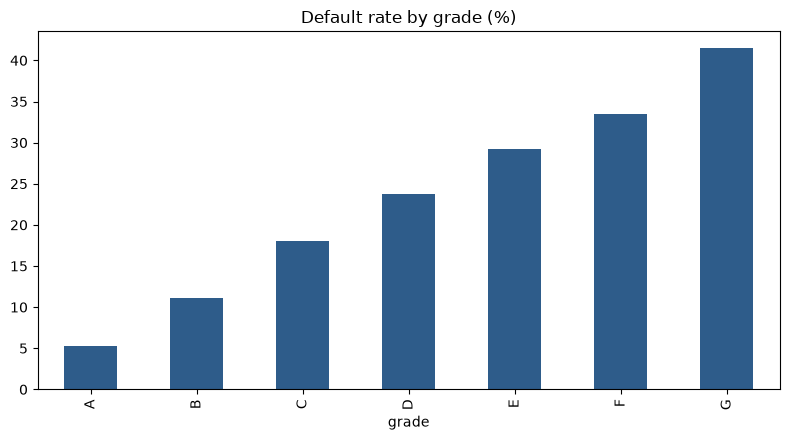

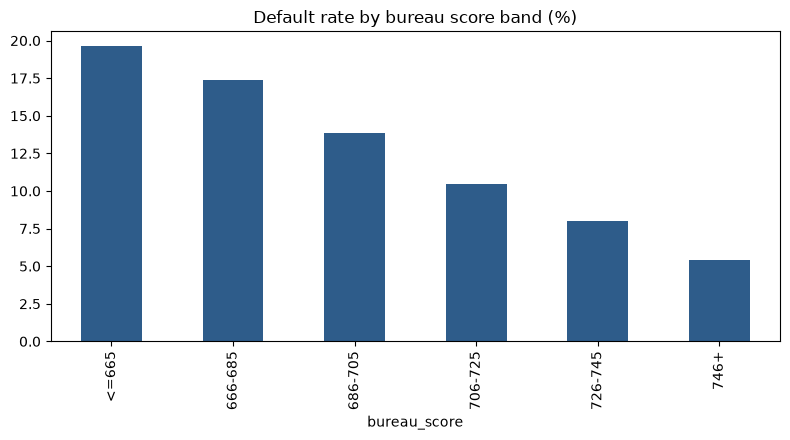

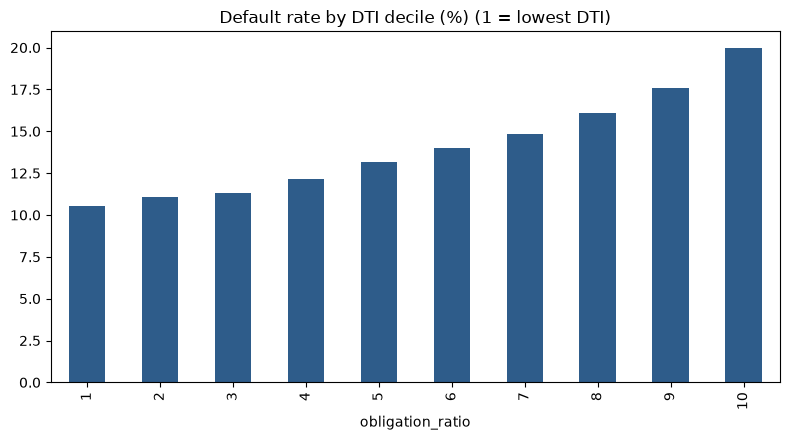

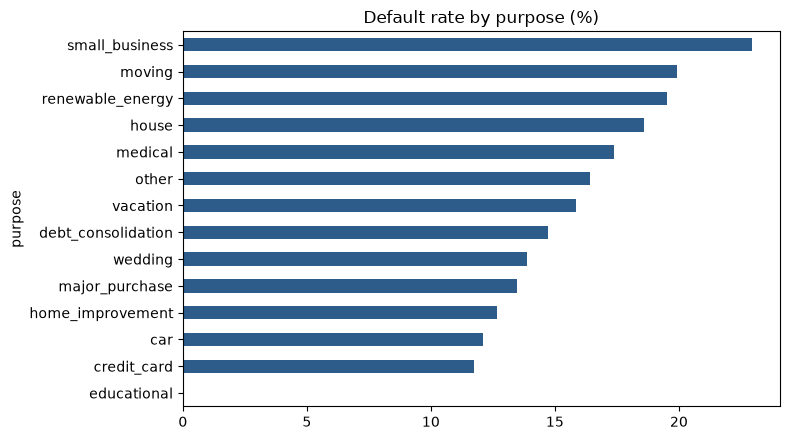

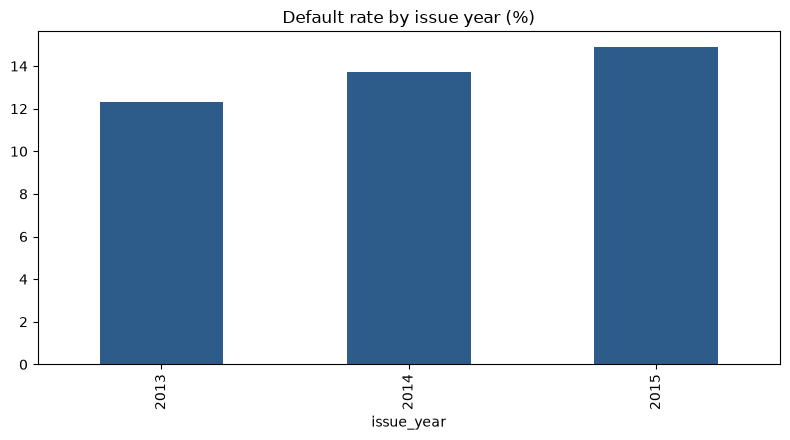

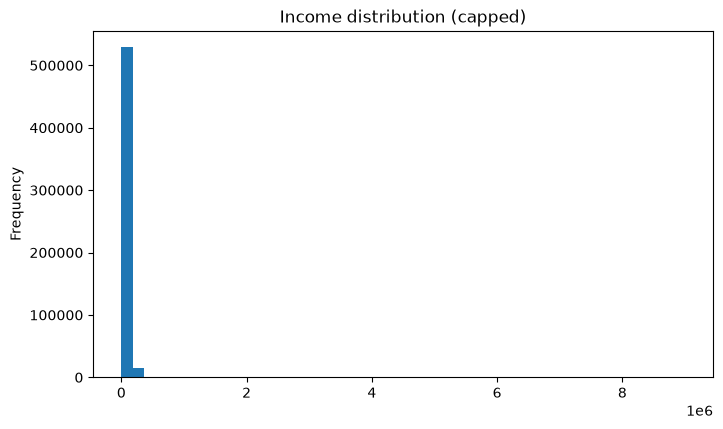

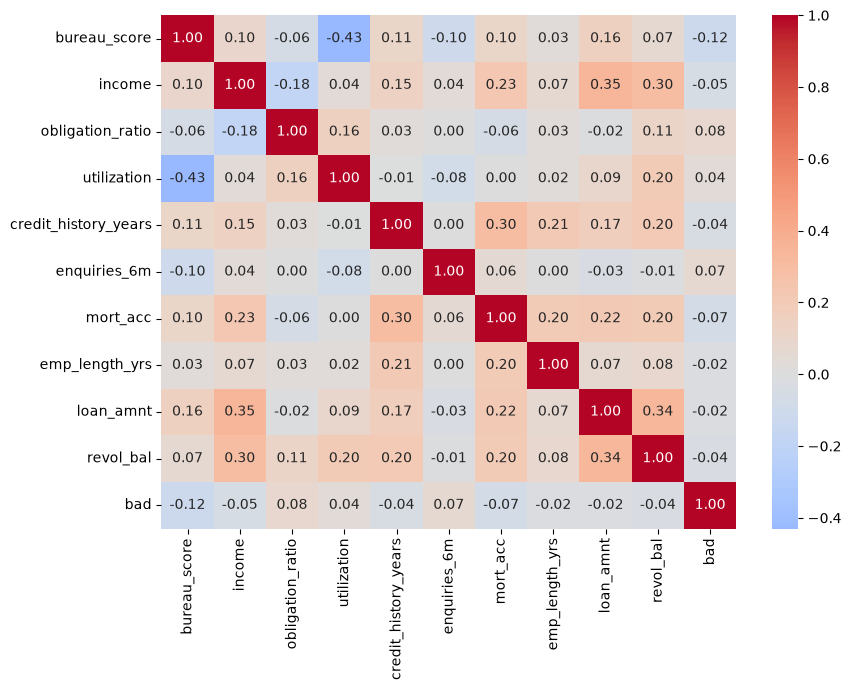

In [11]:
# Defining the function with input variables for default rate Correlation

def rate_chart(groups, title, fname, kind="bar"):
    r = df.groupby(groups, observed=True)["bad"].mean().mul(100)  
    if kind == "barh":
        r = r.sort_values()
    ax = r.plot(kind=kind, figsize=(8, 4.5), color="#2E5C8A")
    ax.set_title(title)
    plt.tight_layout()
    plt.savefig(FOLDER + r"\charts" + "\\" + fname, dpi=120)
    plt.show()
    return r.round(1)

# AS you are seeing With the use of function which defines with various input variables(groupby) we put every releatable value we 
# think Might impact the default rate and see its impact in the form of charts, bar and heatmap.

rate_chart(df["grade"], "Default rate by grade (%)", "01_grade.png")

rate_chart(pd.cut(df["bureau_score"], [0, 665, 685, 705, 725, 745, 900],
           labels=["<=665", "666-685", "686-705", "706-725", "726-745", "746+"]),
           "Default rate by bureau score band (%)", "02_score.png")

rate_chart(pd.qcut(df["obligation_ratio"], 10, labels=False, duplicates="drop") + 1,
           "Default rate by DTI decile (%) (1 = lowest DTI)", "03_dti.png")

rate_chart(df["purpose"], "Default rate by purpose (%)", "04_purpose.png", kind="barh")
rate_chart(df["issue_year"], "Default rate by issue year (%)", "05_year.png")

df["income"].plot(kind="hist", bins=50, figsize=(8, 4.5), title="Income distribution (capped)")
plt.savefig(FOLDER + r"\charts\06_income.png"); plt.show()

cols = ["bureau_score", "income", "obligation_ratio", "utilization", "credit_history_years",
        "enquiries_6m", "mort_acc", "emp_length_yrs", "loan_amnt", "revol_bal", "bad"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.tight_layout(); plt.savefig(FOLDER + r"\charts\07_corr.png"); plt.show()

In [15]:
# We also see other variables correlation with default rates 

print(df.groupby("verification_status")["bad"].mean().round(3))
print(df.groupby("home_ownership")["bad"].mean().round(3))
print(df.groupby("enquiries_6m")["bad"].mean().round(3))
print(df.groupby(pd.cut(df["credit_history_years"],[0, 5, 10, 15, 20, 30, 80]), observed = True)["bad"].mean().round(3))

#Verification: Not Verified 11.5%, Source Verified 14.3%, Verified 16.6%. This looks backwards, but it’s a known pattern: 
#Lending Club verified the riskier applicants. don’t read it as “verification causes default.”
#Home ownership: mortgage 11.4%, own 15.0%, rent 16.7%.
#Enquiries: 12.2% with none, rising to about 21% with 4 or more.
#Credit history: 18.9% under 5 years, falling to about 12% above 20 years.
#Loan amount: no clear trend (14.4%, 15.6%, 14.2%, 13.8%, 12.5% across quintiles), so it’s a weak variable.

verification_status
Not Verified       0.115
Source Verified    0.143
Verified           0.166
Name: bad, dtype: float64
home_ownership
MORTGAGE    0.114
OWN         0.150
RENT        0.167
Name: bad, dtype: float64
enquiries_6m
0.0    0.122
1.0    0.153
2.0    0.180
3.0    0.197
4.0    0.209
5.0    0.207
6.0    0.209
Name: bad, dtype: float64
credit_history_years
(0, 5]      0.189
(5, 10]     0.164
(10, 15]    0.148
(15, 20]    0.132
(20, 30]    0.120
(30, 80]    0.121
Name: bad, dtype: float64


In [18]:
# Time split and save - helps you understand the model compantablity for predicting future outcomes and 
# to resason behind macro economic factors affecting it.
train_all = df[df["issue_year"].isin([2013, 2014])]
oot = df[df["issue_year"] == 2015]
print(len(train_all), len(oot))
print(round(train_all["bad"].mean(), 4), round(oot["bad"].mean(), 4))

df.to_parquet(FOLDER  + r"\lc_clean_v2.parquet", index = False)

262991 283025
0.1319 0.1489
